# Task 4 — Process Improvement Proposal: workflow simulation

Client: **Apex Global Investments** (hypothetical) — high-frequency trading, $1.5bn annual volume.
Current trade workflow (Client Profile Reference Sheet): data entry ~15 min → cross-system validation ~20 min →
compliance approval ~25 min → report generation ~30 min = **90 min**, with a **12% reconciliation error rate**
and about **$500,000 of missed opportunities last quarter**.

This notebook reproduces every number, table and chart in `Process_Improvement_Proposal.tex`:

1. Step times from the profile, and where the time goes → `figures/fig1_step_times.pdf`
2. Monte Carlo simulation of 10,000 trades, current vs. automated → `figures/table1_simulation.tex`, `figures/fig2_distribution.pdf`
3. Impact by phase of the roll-out → `figures/table2_phases.tex`
4. Cost–benefit and sensitivity → `figures/table3_costbenefit.tex`

> **Assumptions.** The step means, the 12% error rate and the $500k figure come from the profile sheet. Variability,
> rework time, the performance of the automated steps and the costs are **stated assumptions**, gathered in one
> cell so they can be challenged and re-run. Results show the size of the gain, not a guarantee.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(42)          # fixed seed: results are reproducible
N_TRADES = 10_000                        # simulated trades

# Two-series palette (validated: lightness, chroma, colour-blind separation, normal-vision floor)
CURRENT_COLOR, PROPOSED_COLOR = "#D9822B", "#2A55B0"     # current = orange, automated = blue
TEXT_COLOR, MUTED_COLOR = "#222222", "#666666"
plt.rcParams.update({"font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#BBBBBB", "axes.labelcolor": TEXT_COLOR,
                     "xtick.color": MUTED_COLOR, "ytick.color": MUTED_COLOR})


def to_latex_number(value, number_format="{:.1f}", show_sign=False):
    """Format a number for a LaTeX table, using a proper minus sign."""
    if show_sign:
        number_format = "{:+" + number_format[2:]
    return number_format.format(value).replace("-", r"\textminus{}")

## 1. Where the time goes (Client Profile Reference Sheet)

In [2]:
STEPS = ["Data entry", "Cross-system validation", "Compliance approval", "Report generation"]
profile_minutes = pd.Series([15, 20, 25, 30], index=STEPS, name="Minutes (profile)")
assert profile_minutes.sum() == 90               # matches 'average trade execution time: 90 minutes'
pd.DataFrame({"Minutes": profile_minutes,
              "Share (%)": (100 * profile_minutes / profile_minutes.sum()).round(1),
              "Before execution?": ["yes", "yes", "yes", "no (post-trade)"]})

,Minutes,Share (%),Before execution?
Data entry,15,16.7,yes
Cross-system validation,20,22.2,yes
Compliance approval,25,27.8,yes
Report generation,30,33.3,no (post-trade)


Three of the four steps happen **before** the trade can be executed: 60 minutes of manual hand-offs.
Compliance approval is the longest pre-trade step (25 min) and cross-system validation is where the 12% of errors appear.

## 2. Assumptions and Monte Carlo simulation of 10,000 trades

In [3]:
ASSUMPTIONS = dict(
    manual_time_variability=0.30,           # coefficient of variation of manual step times
    current_error_rate=0.12,                # reconciliation error rate (profile sheet)
    current_rework_minutes=(20, 25),        # an error means re-validating and re-checking with compliance
    # --- automated workflow ---
    auto_entry_minutes=1.0,                 # API / straight-through capture of trade details
    auto_validation_minutes=2.0,            # rule-based reconciliation engine, exceptions only
    auto_error_rate=0.02,                   # residual exception rate after automated matching
    auto_rework_minutes=10,                 # analyst resolves an exception flagged by the engine
    auto_approval_share=0.85,               # share of trades passing automated pre-trade compliance rules
    auto_approval_minutes=1.0,              # time when the rules pass
    exception_review_minutes=15,            # compliance officer reviews only the flagged exceptions
    auto_report_minutes=2.0,                # templated report generated and distributed automatically
    missed_opportunities_per_quarter=500_000,   # $, profile sheet
)
pd.Series(ASSUMPTIONS, dtype=object)

manual_time_variability                  0.3
current_error_rate                      0.12
current_rework_minutes              (20, 25)
auto_entry_minutes                       1.0
auto_validation_minutes                  2.0
auto_error_rate                         0.02
auto_rework_minutes                       10
auto_approval_share                     0.85
auto_approval_minutes                    1.0
exception_review_minutes                  15
auto_report_minutes                      2.0
missed_opportunities_per_quarter      500000
dtype: object

In [4]:
AUTOMATED_STEP_VARIABILITY = 0.2


def random_step_times(mean_minutes, n_trades, variability=ASSUMPTIONS["manual_time_variability"]):
    """Gamma-distributed step times with the given mean and coefficient of variation."""
    shape = 1 / variability ** 2                   # mean = shape * scale
    return rng.gamma(shape, mean_minutes / shape, n_trades)


def simulate_workflow(entry_minutes, validation_minutes, approval_minutes, report_minutes, error_rate, rework_minutes):
    """Times in minutes for each trade: time to execution, end-to-end time, and whether an error occurred."""
    has_error = rng.random(N_TRADES) < error_rate
    rework = rework_minutes if np.isscalar(rework_minutes) else rng.uniform(*rework_minutes, N_TRADES)
    time_to_execution = entry_minutes + validation_minutes + approval_minutes + has_error * rework
    return pd.DataFrame({"pre_trade": time_to_execution, "end_to_end": time_to_execution + report_minutes,
                         "error": has_error})


current_workflow = simulate_workflow(random_step_times(15, N_TRADES), random_step_times(20, N_TRADES),
                                     random_step_times(25, N_TRADES), random_step_times(30, N_TRADES),
                                     ASSUMPTIONS["current_error_rate"], ASSUMPTIONS["current_rework_minutes"])

passes_compliance_rules = rng.random(N_TRADES) < ASSUMPTIONS["auto_approval_share"]
automated_approval_minutes = np.where(passes_compliance_rules,
                                      random_step_times(ASSUMPTIONS["auto_approval_minutes"], N_TRADES, AUTOMATED_STEP_VARIABILITY),
                                      random_step_times(ASSUMPTIONS["exception_review_minutes"], N_TRADES))
automated_workflow = simulate_workflow(
    random_step_times(ASSUMPTIONS["auto_entry_minutes"], N_TRADES, AUTOMATED_STEP_VARIABILITY),
    random_step_times(ASSUMPTIONS["auto_validation_minutes"], N_TRADES, AUTOMATED_STEP_VARIABILITY),
    automated_approval_minutes,
    random_step_times(ASSUMPTIONS["auto_report_minutes"], N_TRADES, AUTOMATED_STEP_VARIABILITY),
    ASSUMPTIONS["auto_error_rate"], ASSUMPTIONS["auto_rework_minutes"])


def summarise_workflow(trades):
    return {"Average time to execution (min)": trades["pre_trade"].mean(),
            "95th percentile time to execution (min)": trades["pre_trade"].quantile(0.95),
            "Average end-to-end time incl. report (min)": trades["end_to_end"].mean(),
            "Reconciliation error rate (%)": 100 * trades["error"].mean()}


simulation_summary = pd.DataFrame({"Current": summarise_workflow(current_workflow),
                                   "Automated": summarise_workflow(automated_workflow)})
simulation_summary["Change (%)"] = 100 * (simulation_summary["Automated"] / simulation_summary["Current"] - 1)
simulation_summary.round(1)

,Current,Automated,Change (%)
Average time to execution (min),62.7,6.3,-89.9
95th percentile time to execution (min),86.8,20.1,-76.9
Average end-to-end time incl. report (min),92.7,8.3,-91.0
Reconciliation error rate (%),12.1,1.9,-84.4


In [5]:
table_lines = [r"\begin{tabular}{@{}lrrr@{}}", r"\toprule",
               r"\textbf{Metric (10{,}000 simulated trades)} & \textbf{Current} & \textbf{Automated} & \textbf{Change} \\",
               r"\midrule"]
ROW_LABELS = {"Average time to execution (min)": "Average time to execution (min)",
              "95th percentile time to execution (min)": r"Slowest 5\% of trades: time to execution (min)",
              "Average end-to-end time incl. report (min)": r"End-to-end time incl.\ report (min)",
              "Reconciliation error rate (%)": r"Reconciliation error rate (\%)"}
for metric, label in ROW_LABELS.items():
    row = simulation_summary.loc[metric]
    table_lines.append(f"{label} & {to_latex_number(row['Current'])} & {to_latex_number(row['Automated'])} & "
                       f"{to_latex_number(row['Change (%)'], '{:.0f}', show_sign=True)}\\% \\\\")
table_lines += [r"\bottomrule", r"\end{tabular}"]
latex_table = "\n".join(table_lines)
(FIGURES_DIR / "table1_simulation.tex").write_text(latex_table)
print(latex_table)

\begin{tabular}{@{}lrrr@{}}
\toprule
\textbf{Metric (10{,}000 simulated trades)} & \textbf{Current} & \textbf{Automated} & \textbf{Change} \\
\midrule
Average time to execution (min) & 62.7 & 6.3 & \textminus{}90\% \\
Slowest 5\% of trades: time to execution (min) & 86.8 & 20.1 & \textminus{}77\% \\
End-to-end time incl.\ report (min) & 92.7 & 8.3 & \textminus{}91\% \\
Reconciliation error rate (\%) & 12.1 & 1.9 & \textminus{}84\% \\
\bottomrule
\end{tabular}


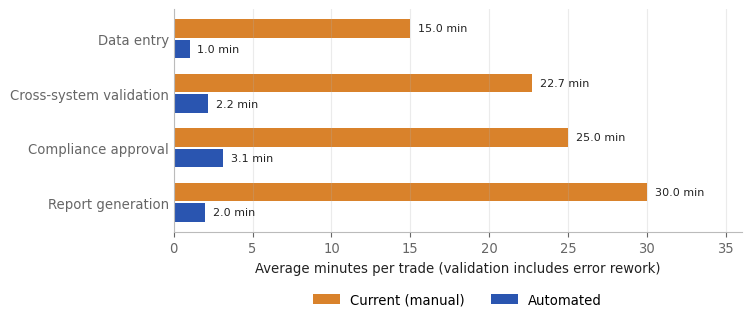

,Current,Automated
Data entry,15.0,1.0
Cross-system validation,22.7,2.2
Compliance approval,25.0,3.1
Report generation,30.0,2.0


In [6]:
# Figure 1 - average minutes per step, current vs automated (validation includes error rework)
current_step_minutes = pd.Series([15, 20 + ASSUMPTIONS["current_error_rate"] * np.mean(ASSUMPTIONS["current_rework_minutes"]), 25, 30],
                                 index=STEPS)
automated_step_minutes = pd.Series([
    ASSUMPTIONS["auto_entry_minutes"],
    ASSUMPTIONS["auto_validation_minutes"] + ASSUMPTIONS["auto_error_rate"] * ASSUMPTIONS["auto_rework_minutes"],
    ASSUMPTIONS["auto_approval_share"] * ASSUMPTIONS["auto_approval_minutes"] + (1 - ASSUMPTIONS["auto_approval_share"]) * ASSUMPTIONS["exception_review_minutes"],
    ASSUMPTIONS["auto_report_minutes"],
], index=STEPS)

fig, ax = plt.subplots(figsize=(7.6, 3.4))
rows = np.arange(len(STEPS))
BAR_HEIGHT = 0.38
for step_minutes, offset, color, label in [(current_step_minutes, -BAR_HEIGHT / 2, CURRENT_COLOR, "Current (manual)"),
                                           (automated_step_minutes, BAR_HEIGHT / 2, PROPOSED_COLOR, "Automated")]:
    bars = ax.barh(rows + offset, step_minutes, height=BAR_HEIGHT - 0.04, color=color, label=label)
    for bar, minutes in zip(bars, step_minutes):
        ax.text(minutes + 0.5, bar.get_y() + bar.get_height() / 2, f"{minutes:.1f} min", va="center",
                fontsize=8, color=TEXT_COLOR)
ax.set_yticks(rows, STEPS)
ax.invert_yaxis()
ax.tick_params(axis="y", length=0)
ax.set_xlabel("Average minutes per trade (validation includes error rework)")
ax.set_xlim(0, 36)
ax.grid(axis="x", alpha=0.25)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig1_step_times.pdf", bbox_inches="tight")
plt.show()
pd.DataFrame({"Current": current_step_minutes, "Automated": automated_step_minutes}).round(1)

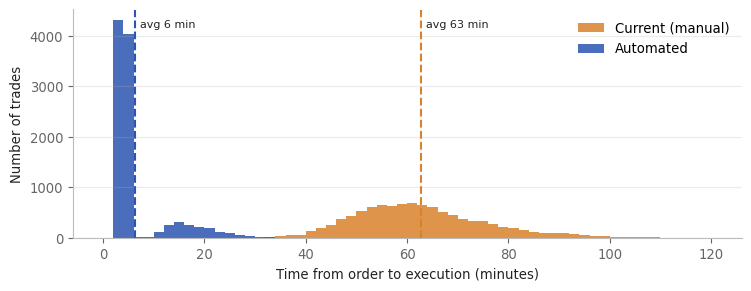

In [7]:
# Figure 2 - distribution of time to execution
fig, ax = plt.subplots(figsize=(7.6, 3.0))
bins = np.arange(0, 121, 2)
ax.hist(current_workflow["pre_trade"], bins=bins, color=CURRENT_COLOR, alpha=0.85, label="Current (manual)")
ax.hist(automated_workflow["pre_trade"], bins=bins, color=PROPOSED_COLOR, alpha=0.85, label="Automated")
for workflow, color in [(current_workflow, CURRENT_COLOR), (automated_workflow, PROPOSED_COLOR)]:
    average_minutes = workflow["pre_trade"].mean()
    ax.axvline(average_minutes, color=color, lw=1.5, ls="--")
    ax.text(average_minutes + 1, ax.get_ylim()[1] * 0.92, f"avg {average_minutes:.0f} min", color=TEXT_COLOR, fontsize=8)
ax.set_xlabel("Time from order to execution (minutes)")
ax.set_ylabel("Number of trades")
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="upper right", frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig2_distribution.pdf", bbox_inches="tight")
plt.show()

## 3. Impact by phase

The roll-out is phased because Apex has **limited IT resources**: each phase must work on its own and be measured before the next.

In [8]:
def simulate_phase(automate_entry, automate_validation, automate_approval, automate_report):
    """Simulate the workflow with only some of the steps automated."""
    entry_minutes = (random_step_times(ASSUMPTIONS["auto_entry_minutes"], N_TRADES, AUTOMATED_STEP_VARIABILITY)
                     if automate_entry else random_step_times(15, N_TRADES))
    validation_minutes = (random_step_times(ASSUMPTIONS["auto_validation_minutes"], N_TRADES, AUTOMATED_STEP_VARIABILITY)
                          if automate_validation else random_step_times(20, N_TRADES))
    if automate_approval:
        passes_rules = rng.random(N_TRADES) < ASSUMPTIONS["auto_approval_share"]
        approval_minutes = np.where(passes_rules,
                                    random_step_times(ASSUMPTIONS["auto_approval_minutes"], N_TRADES, AUTOMATED_STEP_VARIABILITY),
                                    random_step_times(ASSUMPTIONS["exception_review_minutes"], N_TRADES))
    else:
        approval_minutes = random_step_times(25, N_TRADES)
    report_minutes = (random_step_times(ASSUMPTIONS["auto_report_minutes"], N_TRADES, AUTOMATED_STEP_VARIABILITY)
                      if automate_report else random_step_times(30, N_TRADES))
    if automate_validation:
        error_rate, rework_minutes = ASSUMPTIONS["auto_error_rate"], ASSUMPTIONS["auto_rework_minutes"]
    else:
        error_rate, rework_minutes = ASSUMPTIONS["current_error_rate"], ASSUMPTIONS["current_rework_minutes"]
    return simulate_workflow(entry_minutes, validation_minutes, approval_minutes, report_minutes,
                             error_rate, rework_minutes)


phase_workflows = {
    "Today (manual)":                                   simulate_phase(False, False, False, False),
    "Phase 1: reconciliation engine + auto reports":    simulate_phase(False, True,  False, True),
    "Phase 2: + rule-based compliance pre-checks":      simulate_phase(False, True,  True,  True),
    "Phase 3: + automated trade capture (API)":         simulate_phase(True,  True,  True,  True),
}
phase_summary = pd.DataFrame({phase: summarise_workflow(trades) for phase, trades in phase_workflows.items()}).T
phase_summary.round(1)

,Average time to execution (min),95th percentile time to execution (min),Average end-to-end time incl. report (min),Reconciliation error rate (%)
Today (manual),62.8,86.7,92.8,12.1
Phase 1: reconciliation engine + auto reports,42.2,57.6,44.2,2.0
Phase 2: + rule-based compliance pre-checks,20.2,34.7,22.2,2.1
Phase 3: + automated trade capture (API),6.3,19.7,8.3,1.8


In [9]:
table_lines = [r"\begin{tabular}{@{}lrrr@{}}", r"\toprule",
               r"\textbf{Stage} & \textbf{Time to execution} & \textbf{End-to-end} & \textbf{Error rate} \\", r"\midrule"]
for phase, row in phase_summary.iterrows():
    table_lines.append(f"{phase} & {row['Average time to execution (min)']:.0f} min & "
                       f"{row['Average end-to-end time incl. report (min)']:.0f} min & "
                       f"{row['Reconciliation error rate (%)']:.1f}\\% \\\\")
table_lines += [r"\bottomrule", r"\end{tabular}"]
latex_table = "\n".join(table_lines)
(FIGURES_DIR / "table2_phases.tex").write_text(latex_table)
print(latex_table)

\begin{tabular}{@{}lrrr@{}}
\toprule
\textbf{Stage} & \textbf{Time to execution} & \textbf{End-to-end} & \textbf{Error rate} \\
\midrule
Today (manual) & 63 min & 93 min & 12.1\% \\
Phase 1: reconciliation engine + auto reports & 42 min & 44 min & 1.9\% \\
Phase 2: + rule-based compliance pre-checks & 20 min & 22 min & 2.1\% \\
Phase 3: + automated trade capture (API) & 6 min & 8 min & 1.8\% \\
\bottomrule
\end{tabular}


## 4. Cost–benefit

Missed opportunities are assumed to scale with the time a trade waits before execution. Because that link is
uncertain, three cases are shown: only 25%, 50% or 100% of the time saved turns into recovered opportunities.
Costs are illustrative (reconciliation and compliance-rules software, vendor-managed API integration, training).

In [10]:
annual_missed_opportunities = 4 * ASSUMPTIONS["missed_opportunities_per_quarter"]   # $2.0m a year at today's run-rate
time_cut = 1 - (simulation_summary.loc["Average time to execution (min)", "Automated"]
                / simulation_summary.loc["Average time to execution (min)", "Current"])
YEAR_1_COST, YEARLY_RUNNING_COST = 400_000, 120_000                      # $ set-up + licences in year 1, $ per later year

scenario_rows = {}
for share_recovered in [0.25, 0.50, 1.00]:
    annual_benefit = annual_missed_opportunities * time_cut * share_recovered
    scenario_rows[f"{int(share_recovered * 100)}% of time saved is recovered"] = {
        "Annual benefit ($k)": annual_benefit / 1e3,
        "Year-1 net ($k)": (annual_benefit - YEAR_1_COST) / 1e3,
        "Payback (months)": 12 * YEAR_1_COST / annual_benefit,
        "3-year net ($k)": (3 * annual_benefit - YEAR_1_COST - 2 * YEARLY_RUNNING_COST) / 1e3,
    }
cost_benefit = pd.DataFrame(scenario_rows).T
print(f"Time to execution cut by {100 * time_cut:.0f}%; "
      f"missed opportunities today ~${annual_missed_opportunities / 1e6:.1f}m a year")
cost_benefit.round(1)

Time to execution cut by 90%; missed opportunities today ~$2.0m a year


,Annual benefit ($k),Year-1 net ($k),Payback (months),3-year net ($k)
25% of time saved is recovered,449.5,49.5,10.7,708.6
50% of time saved is recovered,899.1,499.1,5.3,2057.3
100% of time saved is recovered,1798.2,1398.2,2.7,4754.6


In [11]:
table_lines = [r"\begin{tabular}{@{}lrrrr@{}}", r"\toprule",
               r"\textbf{Scenario} & \textbf{Annual benefit} & \textbf{Year-1 net} & \textbf{Payback} & \textbf{3-year net} \\",
               r"\midrule"]
for scenario, row in cost_benefit.iterrows():
    scenario_name = scenario.replace("%", r"\%")
    table_lines.append(f"{scenario_name} & \\${row['Annual benefit ($k)']:,.0f}k & "
                       f"\\${to_latex_number(row['Year-1 net ($k)'], '{:,.0f}')}k & "
                       f"{row['Payback (months)']:.1f} months & "
                       f"\\${to_latex_number(row['3-year net ($k)'], '{:,.0f}')}k \\\\")
table_lines += [r"\bottomrule", r"\end{tabular}"]
latex_table = "\n".join(table_lines)
(FIGURES_DIR / "table3_costbenefit.tex").write_text(latex_table)
print(latex_table)

\begin{tabular}{@{}lrrrr@{}}
\toprule
\textbf{Scenario} & \textbf{Annual benefit} & \textbf{Year-1 net} & \textbf{Payback} & \textbf{3-year net} \\
\midrule
25\% of time saved is recovered & \$450k & \$50k & 10.7 months & \$709k \\
50\% of time saved is recovered & \$899k & \$499k & 5.3 months & \$2,057k \\
100\% of time saved is recovered & \$1,798k & \$1,398k & 2.7 months & \$4,755k \\
\bottomrule
\end{tabular}


## Reading

Automating the three pre-trade hand-offs removes most of the waiting time before a trade can be executed, and the
reconciliation engine replaces the step where errors originate. Even if only a quarter of the time saved turns into
recovered opportunities, the investment pays back within about a year under these assumptions.